# Codificación aritmética: interpretar un intervalo y presupuestar los bits

**Tema 2 · Apartados 2.4 · Demostración orientativa: 10–20 minutos.**

Analizar una solución dada, comprobar representantes binarios y estudiar terminación y precisión.

## Cómo experimentar

Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno directamente en el navegador.
«Descargar cuaderno .ipynb» permite guardarlo y abrirlo en Jupyter o importarlo en Colab.
Puedes guardar una copia en tu Google Drive o descargar tu cuaderno desde Colab para conservar cambios.
Los cambios en tu sesión no modifican los originales de este repositorio.
La vista HTML muestra los resultados guardados; no recalcula las gráficas.
Los datos se generan en el propio cuaderno. No se instalan paquetes ni se descargan datos.
Solo se necesitan NumPy, Matplotlib y la biblioteca estándar de Python; IPython muestra las tablas.

## Modelo y pregunta

Partimos de **dos ejemplos ya resueltos**, cuyas tablas de intervalos están dadas:

| Caso | Fuente y secuencia | Intervalos sucesivos |
|---|---|---|
| clase | P(0)=2/5; `10110` | [2/5,1), [2/5,16/25), [62/125,16/25), [346/625,16/25), [346/625,1838/3125) |
| equiprobable | P(0)=1/2; `010` | [0,1/2), [1/4,1/2), [1/4,3/8) |

El código interpreta estas tablas; no genera los intervalos ni codifica o decodifica una secuencia.
Queremos resolver tres preguntas: ¿la fracción binaria propuesta pertenece al intervalo final?,
¿cuántos bits prescribe la regla suficiente de la teoría?, ¿cómo cambia el presupuesto por símbolo
cuando crece el bloque?

Para la palabra dada $b_1\ldots b_k$, calculamos únicamente su valor numérico
$M=0.b_1\ldots b_k$ y comprobamos $a_n\leq M<b_n$.
También mostramos $[M,M+2^{-k})$, el conjunto de números que comparten ese prefijo binario.
Que el punto pertenezca a $I_n$ y que el intervalo diádico completo esté contenido son condiciones distintas.
La primera permite identificar la secuencia cuando se conoce $n$ y el modelo; la segunda es más fuerte.

In [1]:
import math
import html
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
AZUL = '#006d75'
NARANJA = '#b95028'
GRIS = '#617583'

def tabla(cabeceras, filas):
    def celda(x):
        return html.escape(str(x))
    cuerpo = ''.join('<tr>' + ''.join('<td>' + celda(x) + '</td>' for x in fila)
                     + '</tr>' for fila in filas)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'
                 + ''.join('<th>' + celda(x) + '</th>' for x in cabeceras)
                 + '</tr></thead><tbody>' + cuerpo + '</tbody></table></div>'))

def entropia(prob):
    p = np.asarray(prob, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
caso = "clase" #@param ["clase", "equiprobable"]
palabra_propuesta = "100100" #@param {type:"string"}
prob_cero_presupuesto = 0.9 #@param {type:"slider", min:0.01, max:0.99, step:0.01}
longitud_bloque = 256 #@param {type:"integer"}
precision_bits = 53 #@param {type:"slider", min:24, max:128, step:1}
assert caso in ['clase', 'equiprobable']
assert isinstance(palabra_propuesta, str) and 1 <= len(palabra_propuesta) <= 20
assert set(palabra_propuesta) <= {'0', '1'}
assert .01 <= prob_cero_presupuesto <= .99
assert isinstance(longitud_bloque, int) and 1 <= longitud_bloque <= 10000
assert isinstance(precision_bits, int) and 24 <= precision_bits <= 128
datos = {
    'clase': {'secuencia': '10110', 'p0': Fraction(2, 5),
              'intervalos': [('2/5', '1'), ('2/5', '16/25'), ('62/125', '16/25'),
                             ('346/625', '16/25'), ('346/625', '1838/3125')]},
    'equiprobable': {'secuencia': '010', 'p0': Fraction(1, 2),
                    'intervalos': [('0', '1/2'), ('1/4', '1/2'), ('1/4', '3/8')]},
}
dato = datos[caso]
intervalos = [(Fraction(a), Fraction(b)) for a, b in dato['intervalos']]
a, b = intervalos[-1]
k_propuesto = len(palabra_propuesta)
M = Fraction(int(palabra_propuesta, 2), 2**k_propuesto)
fin_diadico = M+Fraction(1, 2**k_propuesto)
punto_valido = a <= M < b
prefijo_contenido = a <= M and fin_diadico <= b
k_regla = math.ceil(math.log2(1/float(b-a)))+1

## 1. Interpretar la tabla y comprobar una propuesta

Las barras muestran los intervalos dados en **una escala absoluta compartida**.
La segunda figura amplía el intervalo final y la propuesta binaria.
No se deduce ni se transmite el siguiente símbolo: se verifica una solución propuesta.
Para el caso equiprobable, puedes proponer `010` o `0101`.

Paso,Símbolo dado,a_i,b_i,Anchura
1,1,2/5,1,3/5
2,0,2/5,16/25,6/25
3,1,62/125,16/25,18/125
4,1,346/625,16/25,54/625
5,0,346/625,1838/3125,108/3125


Caso clase: secuencia dada 10110, P(0) = 2/5.
Anchura final = 108/3125; regla suficiente: k = 6 bits.
Propuesta 100100: M = 9/16, con 6 bits.
El punto pertenece al intervalo final.
Todo el intervalo diádico está contenido.


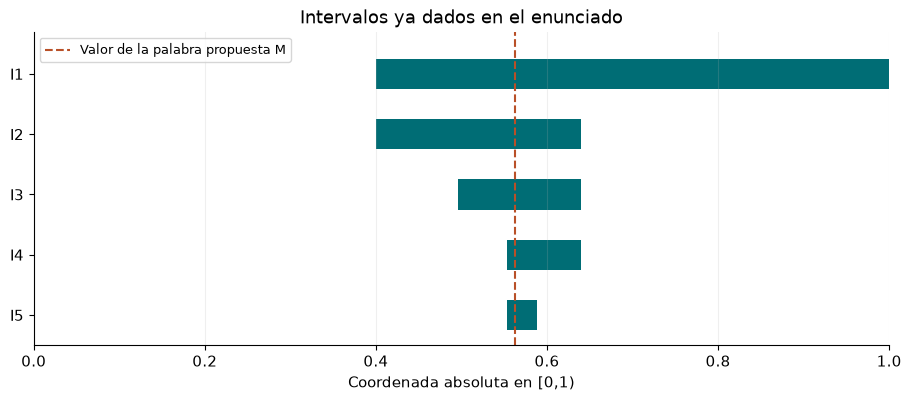

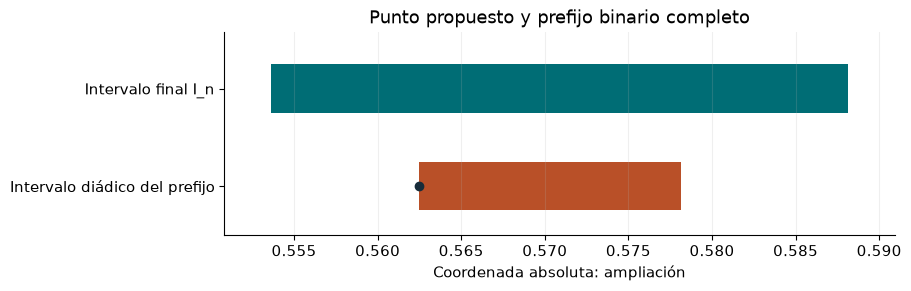

In [3]:
tabla(['Paso', 'Símbolo dado', 'a_i', 'b_i', 'Anchura'],
      [(j, s, str(ai), str(bi), str(bi-ai))
       for j, (s, (ai, bi)) in enumerate(zip(dato['secuencia'], intervalos), 1)])
print(f"Caso {caso}: secuencia dada {dato['secuencia']}, P(0) = {dato['p0']}.")
print(f'Anchura final = {b-a}; regla suficiente: k = {k_regla} bits.')
print(f'Propuesta {palabra_propuesta}: M = {M}, con {k_propuesto} bits.')
print('El punto pertenece al intervalo final.' if punto_valido else 'El punto NO pertenece al intervalo final.')
print('Todo el intervalo diádico está contenido.' if prefijo_contenido else 'El intervalo diádico NO está contenido por completo.')
fig, ax = plt.subplots(figsize=(9, 3.9), layout='constrained')
for fila, (ai, bi) in enumerate(intervalos):
    ax.broken_barh([(float(ai), float(bi-ai))], (fila-.25, .5), facecolors=AZUL)
ax.axvline(float(M), color=NARANJA, ls='--', label='Valor de la palabra propuesta M')
ax.set_yticks(range(len(intervalos)), [f'I{j}' for j in range(1, len(intervalos)+1)])
ax.set(xlim=(0, 1), ylim=(len(intervalos)-.5, -.7), xlabel='Coordenada absoluta en [0,1)',
       title='Intervalos ya dados en el enunciado')
ax.legend(fontsize=9); ax.grid(axis='x', alpha=.2); plt.show()
fig, ax = plt.subplots(figsize=(9, 2.8), layout='constrained')
ax.broken_barh([(float(a), float(b-a))], (.65, .3), facecolors=AZUL)
ax.broken_barh([(float(M), float(fin_diadico-M))], (.05, .3), facecolors=NARANJA)
ax.plot(float(M), .2, 'o', c='#172c3a')
extremos = [float(a), float(b), float(M), float(fin_diadico)]
margen = max(extremos)-min(extremos)
ax.set(xlim=(min(extremos)-.08*margen, max(extremos)+.08*margen), ylim=(-.1, 1.15),
       xlabel='Coordenada absoluta: ampliación', title='Punto propuesto y prefijo binario completo')
ax.set_yticks([.8, .2], ['Intervalo final I_n', 'Intervalo diádico del prefijo'])
ax.grid(axis='x', alpha=.2); plt.show()

## 2. Resolver un presupuesto de longitud y precisión

Esta parte usa una fuente binaria **independiente de la tabla anterior**, con la probabilidad configurable.
No simulamos un codificador. Representamos la cota teórica de su longitud media para la regla suficiente:
$$H(X)\leq E[k]/n < H(X)+2/n.$$
La zona sombreada contiene la **esperanza**; no predice exactamente el tamaño de un bloque concreto.
La línea superior es una cota, no una medición de compresión.

Un bloque con información cercana a $nH$ tiene anchura del orden de $2^{-nH}$.
Para un intervalo ubicado en una región como [1/2,1), una precisión de $b$ bits tiene una separación
entre números del orden de $2^{-b}$. Comparar $nH$ con $b$ ilustra cuándo los extremos pueden
resultar difíciles de distinguir. Es una estimación de resolución, no una prueba de fallo de todos
los bloques ni de desbordamiento numérico. Los sistemas reales usan renormalización.

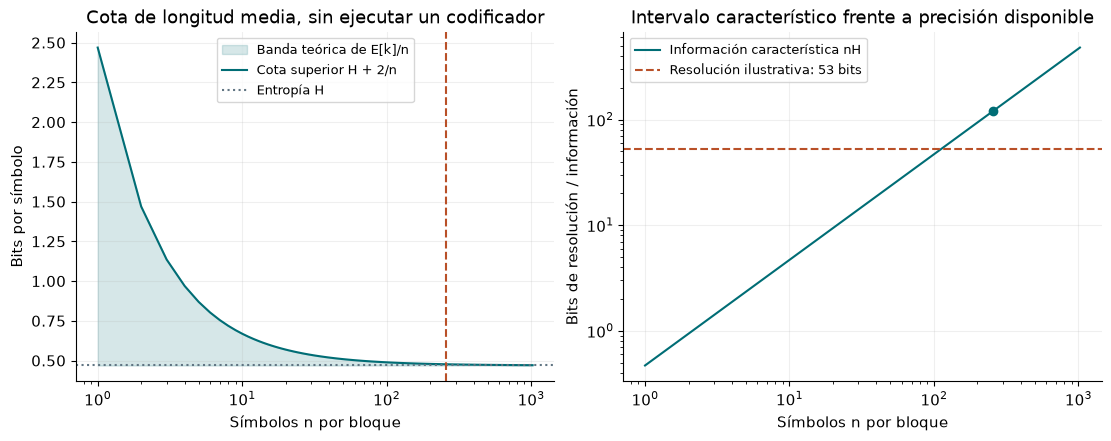

Presupuesto: H = 0.468996; n = 256; nH = 120.063 bits.
Cota: 0.468996 ≤ E[k]/n < 0.476808.
Anchura característica: 2^(-120.063); precisión ilustrativa: 2^(-53).
Cruce aproximado de las escalas: n = b/H ≈ 113.0 símbolos.


In [4]:
H_pres = entropia([prob_cero_presupuesto, 1-prob_cero_presupuesto])
ns = np.unique(np.geomspace(1, max(1024, longitud_bloque), 120).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout='constrained')
axes[0].fill_between(ns, H_pres, H_pres+2/ns, color=AZUL, alpha=.16, label='Banda teórica de E[k]/n')
axes[0].plot(ns, H_pres+2/ns, color=AZUL, label='Cota superior H + 2/n')
axes[0].axhline(H_pres, color=GRIS, ls=':', label='Entropía H')
axes[0].axvline(longitud_bloque, color=NARANJA, ls='--')
axes[0].set(xscale='log', xlabel='Símbolos n por bloque', ylabel='Bits por símbolo',
            title='Cota de longitud media, sin ejecutar un codificador')
axes[0].legend(fontsize=9)
axes[1].plot(ns, ns*H_pres, color=AZUL, label='Información característica nH')
axes[1].axhline(precision_bits, color=NARANJA, ls='--', label=f'Resolución ilustrativa: {precision_bits} bits')
axes[1].scatter([longitud_bloque], [longitud_bloque*H_pres], color=AZUL)
axes[1].set(xscale='log', yscale='log', xlabel='Símbolos n por bloque', ylabel='Bits de resolución / información',
            title='Intervalo característico frente a precisión disponible')
axes[1].legend(fontsize=9)
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Presupuesto: H = {H_pres:.6f}; n = {longitud_bloque}; nH = {longitud_bloque*H_pres:.3f} bits.')
print(f'Cota: {H_pres:.6f} ≤ E[k]/n < {H_pres+2/longitud_bloque:.6f}.')
print(f'Anchura característica: 2^(-{longitud_bloque*H_pres:.3f}); precisión ilustrativa: 2^(-{precision_bits}).')
print(f'Cruce aproximado de las escalas: n = b/H ≈ {precision_bits/H_pres:.1f} símbolos.')

## Antes de mirar la explicación

1. En el caso de clase, compara `1001`, `10010`, `100100`, `100101` y `100110`.
   ¿Pertenecen todos los puntos al intervalo final? ¿Qué prefijos quedan contenidos por completo?
2. ¿Que `1001` use menos de seis bits significa que la regla suficiente sea incorrecta?
3. En el caso equiprobable, compara `010` y `0101`.
4. En el presupuesto, ¿qué cambia al duplicar n? ¿Y al aumentar la precisión?
5. Con P(0)=0.9 y n=256, ¿qué rango de longitud media por símbolo establece la teoría?

## Explicación de lo observado

1. `1001`, `10010` y `100100` representan el mismo punto $9/16$, que pertenece al intervalo final.
   Solo el tercero de esos prefijos queda contenido por completo. `100101` representa $37/64$:
   su punto pertenece, pero su intervalo diádico sobrepasa el extremo superior.
   `100110` representa $19/32$, que ya queda fuera del intervalo.
2. No. La regla de seis bits es **suficiente**, no necesariamente mínima. El receptor conoce
   la longitud original y el modelo. Comprobar un representante concreto no demuestra que pueda
   asignarse esa misma longitud a todos los mensajes de la fuente.
3. `010` representa $1/4$, la frontera inferior incluida. Su intervalo diádico es exactamente
   $[1/4,3/8)$ y bastan tres bits para este caso. La regla suficiente da cuatro; `0101` también sirve.
4. Al duplicar n, el exceso máximo de dos bits por bloque se divide entre el doble de símbolos.
   La información característica nH se duplica y la anchura característica se eleva al cuadrado.
   Aumentar la precisión mejora la resolución; no modifica la entropía ni la probabilidad de la fuente.
5. $H\simeq0.468996$ y $H+2/256\simeq0.476808$ bits/símbolo.
   Se trata de la esperanza, sin contar metadatos del modelo ni la longitud original.

## Comprobación del modelo

Comprobamos las tablas dadas y las identidades de presupuesto.

In [5]:
assert all(ai < bi for ai, bi in intervalos)
assert all(ai <= aj and bj <= bi for (ai, bi), (aj, bj) in zip(intervalos, intervalos[1:]))
assert b-a == dato['p0']**dato['secuencia'].count('0')*(1-dato['p0'])**dato['secuencia'].count('1')
assert Fraction(346, 625) <= Fraction(9, 16) < Fraction(1838, 3125)
assert Fraction(9, 16)+Fraction(1, 64) <= Fraction(1838, 3125)
assert np.isclose((H_pres+2/longitud_bloque-H_pres)*longitud_bloque, 2)
print('Tablas dadas, pertenencia y presupuesto comprobados; no se genera ninguna codificación.')

Tablas dadas, pertenencia y presupuesto comprobados; no se genera ninguna codificación.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 2, apartados 2.4: «Codificación aritmética: intervalos, selección de palabra y eficiencia asintótica».

Los supuestos y las convenciones de este experimento se explican en «Modelo y pregunta».